# Notebook 03 — Implied Volatility Solver & The SPY Volatility Smile

**Goal:** Invert the Black–Scholes formula using Brent's root-finding method (`scipy.optimize.brentq`), clean an SPY option-chain snapshot (using mid prices, filtering wide spreads and zero-bid quotes, and keeping liquid out-of-the-money contracts), and plot the **implied volatility skew**.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import matplotlib.pyplot as plt
from src.black_scholes import bs_price, implied_vol
from src.smile import load_or_fetch_spy_snapshot, clean_chain

# Part 1: Round-Trip Verification of implied_vol() on a Grid
for sig_test in [0.12, 0.20, 0.35, 0.60]:
    for kind in ["call", "put"]:
        theo_p = bs_price(100.0, 105.0, 0.5, 0.03, sig_test, q=0.01, kind=kind)
        recovered_sig = implied_vol(theo_p, 100.0, 105.0, 0.5, 0.03, q=0.01, kind=kind)
        assert abs(recovered_sig - sig_test) < 1e-8
print("Round-trip implied_vol(bs_price(sigma)) == sigma verified across grid!")

Round-trip implied_vol(bs_price(sigma)) == sigma verified across grid!


In [2]:
# Part 2: Load Saved SPY Snapshot and Clean Option Chain
parquet_file = str(Path.cwd().parent / "data" / "spy_chain_snapshot.parquet")
raw_df, S, T, r, q = load_or_fetch_spy_snapshot(parquet_file)
cleaned, stats = clean_chain(raw_df, S, T, r, q)

print(f"Snapshot Parameters: Spot S = {S}, T = {T:.4f} yr, r = {r:.3f}, q = {q:.3f}")
print("\nCleaning Filter Counts:")
for stage, count in stats.items():
    print(f"  {stage:<26}: {count}")

cleaned.head(10)

Snapshot Parameters: Spot S = 580.0, T = 0.1233 yr, r = 0.045, q = 0.012

Cleaning Filter Counts:
  initial_rows              : 58
  after_positive_bid        : 57
  after_spread_filter       : 56
  after_activity_filter     : 56
  after_otm_selection       : 28
  final_valid_iv            : 28


,strike,bid,ask,volume,openInterest,kind,mid,spread_pct,log_moneyness,iv
0,500.0,0.40,0.42,250,1500,put,0.410,0.048780,-0.152488,0.223003
1,505.0,0.48,0.50,250,1500,put,0.490,0.040816,-0.142538,0.217024
2,510.0,0.59,0.61,250,1500,put,0.600,0.033333,-0.132686,0.211905
3,515.0,0.72,0.74,250,1500,put,0.730,0.027397,-0.122930,0.206505
4,520.0,0.88,0.91,250,1500,put,0.895,0.033520,-0.113268,0.201381
5,525.0,1.08,1.12,250,1500,put,1.100,0.036364,-0.103698,0.196343
6,530.0,1.34,1.38,250,1500,put,1.360,0.029412,-0.094220,0.191571
7,535.0,1.66,1.71,250,1500,put,1.685,0.029674,-0.084830,0.186931
8,540.0,2.06,2.12,250,1500,put,2.090,0.028708,-0.075527,0.182408
9,545.0,2.56,2.63,250,1500,put,2.595,0.026975,-0.066311,0.178039


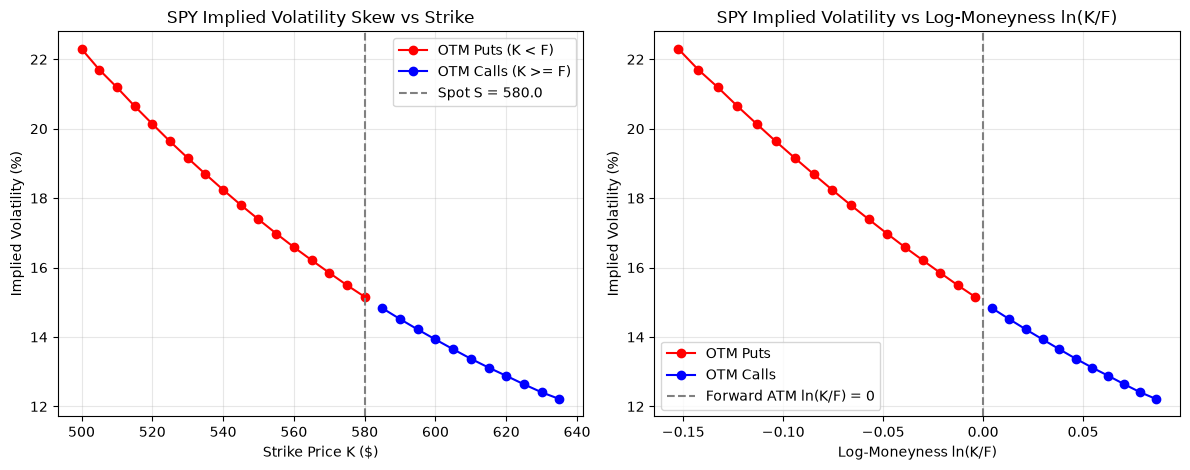

In [3]:
# Part 3: Plot Implied Volatility vs Strike (K) and Log-Moneyness ln(K/F)
puts = cleaned[cleaned["kind"] == "put"]
calls = cleaned[cleaned["kind"] == "call"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

axes[0].plot(puts["strike"], puts["iv"] * 100, "ro-", label="OTM Puts (K < F)")
axes[0].plot(calls["strike"], calls["iv"] * 100, "bo-", label="OTM Calls (K >= F)")
axes[0].axvline(S, color="gray", linestyle="--", label=f"Spot S = {S}")
axes[0].set_title("SPY Implied Volatility Skew vs Strike")
axes[0].set_xlabel("Strike Price K ($)")
axes[0].set_ylabel("Implied Volatility (%)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(puts["log_moneyness"], puts["iv"] * 100, "ro-", label="OTM Puts")
axes[1].plot(calls["log_moneyness"], calls["iv"] * 100, "bo-", label="OTM Calls")
axes[1].axvline(0.0, color="gray", linestyle="--", label="Forward ATM ln(K/F) = 0")
axes[1].set_title("SPY Implied Volatility vs Log-Moneyness ln(K/F)")
axes[1].set_xlabel("Log-Moneyness ln(K/F)")
axes[1].set_ylabel("Implied Volatility (%)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(Path.cwd().parent / "report" / "figures" / "03_volatility_smile.png", dpi=200)
plt.show()

## Part 4: Why Constant-$\sigma$ Black–Scholes Fails & Limitations

If the assumptions of Black–Scholes held in reality, implied volatility across all strikes $K$ would be a flat horizontal line. Instead, the SPY option chain exhibits a steep **downward skew (smirk)**:

1. **Fat Tails and Jump Risk (Project 1 Evidence):** Daily equity index returns exhibit high excess kurtosis and heavy left tails. Deep out-of-the-money puts have a much higher probability of paying off during market crashes than a log-normal distribution allows.
2. **Negative Skew and Leverage Effect (Project 1 & Project 2 Evidence):** Falling equity prices increase corporate leverage and trigger sharper volatility spikes than rising prices ($\gamma > 0$ in our GJR-GARCH model from Project 2), causing downside strikes to trade at higher implied volatilities.
3. **Stochastic, Clustering Volatility (Project 2 Evidence):** Volatility is time-varying and persistent rather than constant over $[0, T]$.
4. **Crash-Protection Demand:** Institutional hedging demand for OTM index puts bids up their market prices, adding an empirical crash-risk premium.

**Limitations to Note:**
* SPY options are **American-style**, whereas `implied_vol` inverts the **European** Black–Scholes formula. Using only out-of-the-money (OTM) options minimizes the early-exercise premium distortion but does not eliminate it completely.
* The option chain is a single point-in-time snapshot, and $r$ and $q$ are treated as constant approximations over the maturity horizon.